In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier 
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
df = pd.read_csv('Titanic.csv')

df = df.drop(['deck', 'adult_male', 'who', 'Unnamed: 0', 'embarked', 'alive'], axis=1)
df['age']= df['age'].fillna(round(df['age'].mean()))
df
columns = df[['embark_town','class', 'alone', 'sex' ]] 
le = LabelEncoder()
for col in columns:
    df[col] = le.fit_transform(df[col])

x = df.drop(['survived'], axis=1)
y= df['survived']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

for_scale = ['fare', 'age']
scaler = StandardScaler()

x_train[for_scale] = scaler.fit_transform(x_train[for_scale])
x_test[for_scale] = scaler.transform(x_test[for_scale])


model_list = {'Rf': RandomForestClassifier(random_state=42, class_weight='balanced').fit(x_train, y_train),
'Lg': LogisticRegression(random_state=42, class_weight='balanced').fit(x_train, y_train),
'XGB': XGBClassifier(random_state=42).fit(x_train, y_train),
'DC' :DecisionTreeClassifier(random_state=42).fit(x_train, y_train),
'Cat': CatBoostClassifier(random_state=42, verbose=0).fit(x_train, y_train),
'LGBM': LGBMClassifier(random_state=42, verbose=-1).fit(x_train, y_train)}
df



,survived,pclass,sex,age,sibsp,parch,fare,class,embark_town,alone
0,0,3,1,22.0,1,0,7.2500,2,2,0
1,1,1,0,38.0,1,0,71.2833,0,0,0
2,1,3,0,26.0,0,0,7.9250,2,2,1
3,1,1,0,35.0,1,0,53.1000,0,2,0
4,0,3,1,35.0,0,0,8.0500,2,2,1
...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,1,2,1
887,1,1,0,19.0,0,0,30.0000,0,2,1
888,0,3,0,30.0,1,2,23.4500,2,2,0
889,1,1,1,26.0,0,0,30.0000,0,0,1


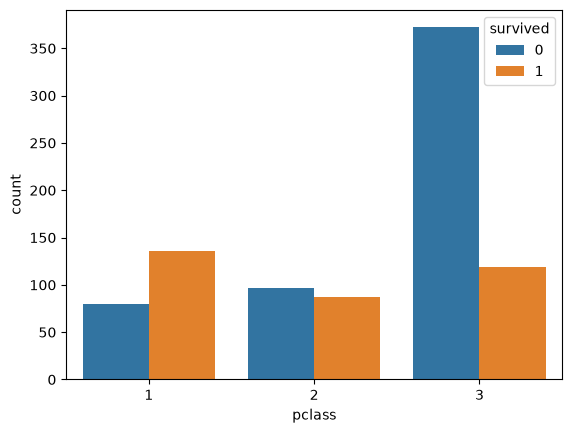

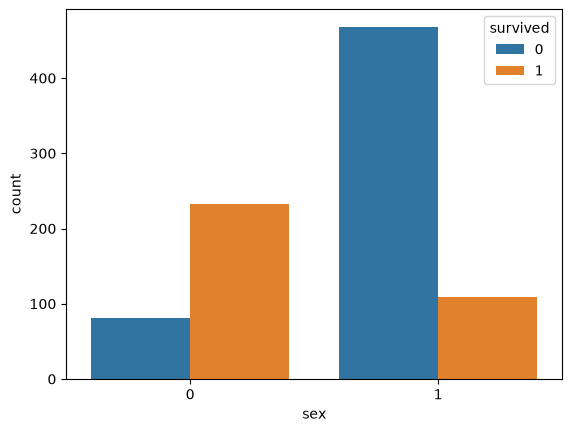

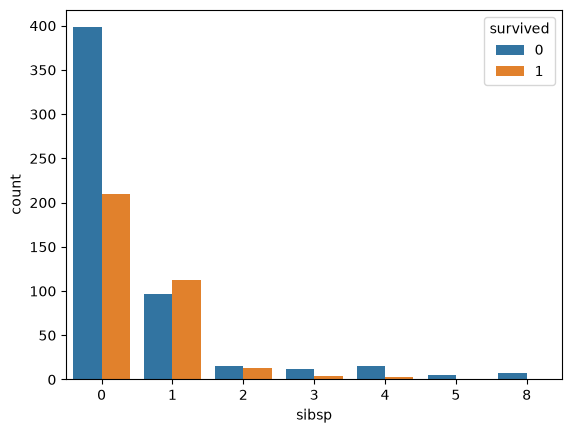

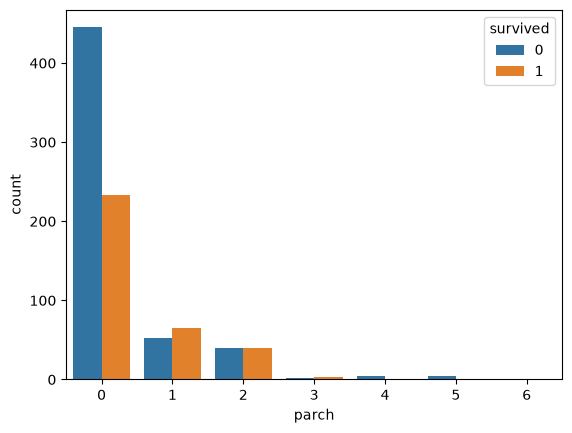

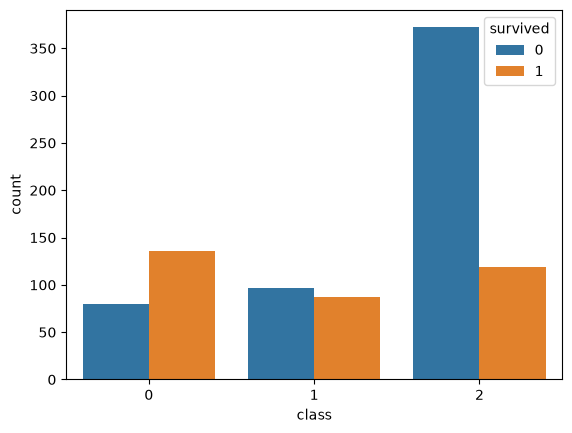

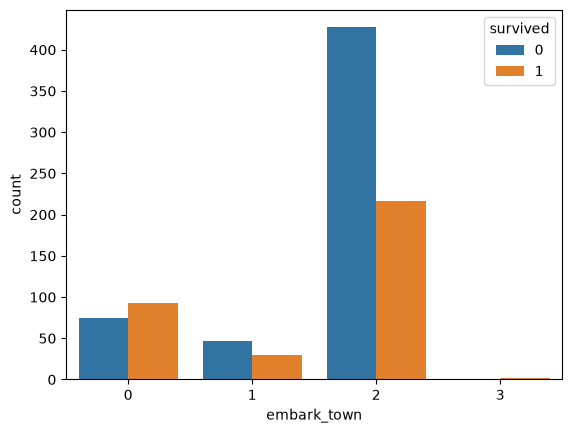

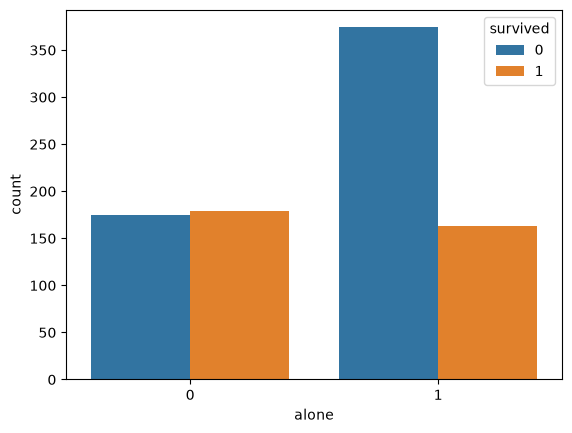

In [2]:
cols = ['pclass', 'sex', 'sibsp', 'parch', 'class', 'embark_town', 'alone']
for col in cols:
    sns.countplot(data=df, x=col, hue='survived')
    plt.show()

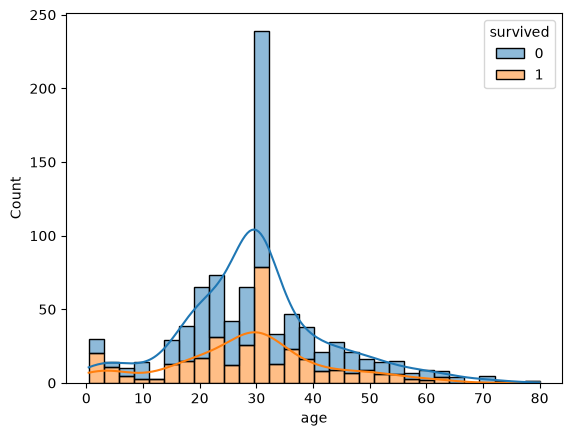

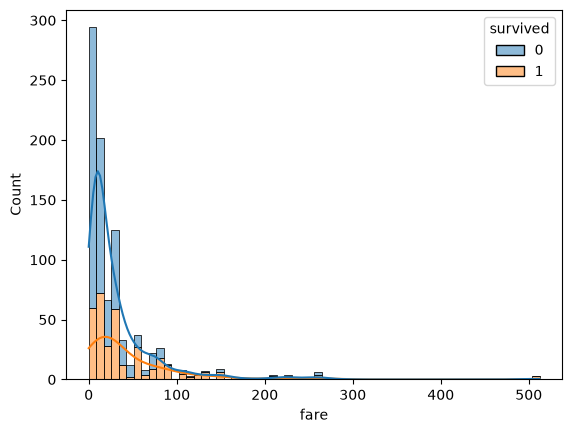

In [10]:
cols = ['age', 'fare']
for col in cols:
    sns.histplot(data=df, x=col, hue='survived', kde=True, multiple='stack')
    plt.show()

In [2]:
def model_f1(model_list):
    for name, model in model_list.items():
        model_pred = model.predict(x_test)
        print(f'f1 {name}: {f1_score(y_test, model_pred)}')
model_f1(model_list)

f1 Rf: 0.723404255319149
f1 Lg: 0.7634408602150538
f1 XGB: 0.7222222222222222
f1 DC: 0.6519337016574586
f1 Cat: 0.7831325301204819
f1 LGBM: 0.7865168539325843


In [3]:
def model_accuracy(model_list):
    for name, model in model_list.items():
        model_pred = model.predict(x_test)
        print(f'accuracy {name}: {accuracy_score(y_test, model_pred)}')

model_accuracy(model_list)

accuracy Rf: 0.7668161434977578
accuracy Lg: 0.8026905829596412
accuracy XGB: 0.7757847533632287
accuracy DC: 0.7174887892376681
accuracy Cat: 0.8385650224215246
accuracy LGBM: 0.8295964125560538


In [10]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [45]:
xgb = XGBClassifier()
param_grid_xgb = {
    'n_estimators': [200, 300],       
     'max_depth': [7, 10],                 
     'learning_rate': [0.05, 0.1],     
     'min_child_weight': [1, 3],          
     'subsample': [0.8],          
     'colsample_bytree': [0.8],   
     'scale_pos_weight': [3]   }               
grid = GridSearchCV(xgb, param_grid_xgb, cv=5, scoring='f1').fit(x_train, y_train)
best_params = grid.best_params_
best_model = grid.best_estimator_
xgb_pred = best_model.predict(x_test)
print(f'f1_xgb: {f1_score(y_test, xgb_pred)}')
print(best_params)

f1_xgb: 0.751269035532995
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 300, 'scale_pos_weight': 3, 'subsample': 0.8}


In [ ]:
rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', 'balanced_subsample', None]
}
grid = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='f1', n_jobs=-1).fit(x_train, y_train)
best_params = grid.best_params_
best_model_rf = grid.best_estimator_
rf_pred = best_model_rf.predict(x_test)
print(f'f1_rf: {f1_score(y_test, rf_pred)}')
print(best_params)

f1_rf: 0.7650273224043715
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}


In [ ]:
import warnings
warnings.filterwarnings('ignore')
lg = LogisticRegression(random_state=42)
param_grid_lg = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],          
    'penalty': ['l1', 'l2'],                       
    'solver': ['liblinear', 'saga']                
}

grid = GridSearchCV(estimator=lg, param_grid=param_grid_lg, cv=5, scoring='f1', n_jobs=-1).fit(x_train, y_train)
best_params = grid.best_params_
best_model_lg = grid.best_estimator_
lg_pred = best_model_lg.predict(x_test)
print(f'f1_lg: {f1_score(y_test, lg_pred)}')
print(best_params)

f1_lg: 0.7398843930635838
{'C': 1, 'penalty': 'l2', 'solver': 'saga'}


In [46]:
lgbm = LGBMClassifier(random_state=42, verbose=-1) 
# params = lgbm.get_params()
# for key, value in params.items():
#     print(f"{key}: {value}")
lgbm_param_grid = {
    'num_leaves': [31],
    'max_depth': [-1],
    'min_child_samples': [20],
    'learning_rate': [0.1],
    'n_estimators': [100]
}

grid = GridSearchCV(lgbm, param_grid=lgbm_param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1).fit(x_train, y_train)

best_lgbm_params = grid.best_params_
best_lgbm_model = grid.best_estimator_

lgbm_pred = best_lgbm_model.predict(x_test)
print(f'f1_lgbm : {f1_score(y_test, lgbm_pred)}')
print(best_lgbm_params)


Fitting 5 folds for each of 1 candidates, totalling 5 fits
f1_lgbm : 0.7865168539325843
{'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 31}


In [31]:
cat = CatBoostClassifier(random_state=42, verbose=0)
cat_param_grid = {
    'iterations': [50, 100, 200],
    'depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7]
}

grid = GridSearchCV(cat, param_grid=cat_param_grid, cv=5, scoring ='f1', n_jobs=-1, verbose=1).fit(x_train, y_train)

best_cat_params = grid.best_params_
best_cat_model = grid.best_estimator_

cat_pred = best_cat_model.predict(x_test)

print(f'f1_cat : {f1_score(y_test, cat_pred)}')
print(best_cat_params)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
f1_cat : 0.7764705882352941
{'depth': 5, 'iterations': 200, 'l2_leaf_reg': 7, 'learning_rate': 0.1}


In [4]:
import warnings
warnings.filterwarnings('ignore')
after_grid = {'xgb_after_grid_params' : XGBClassifier(colsample_bytree = 0.8, learning_rate = 0.05, max_depth= 10, min_child_weight= 3, n_estimators= 300, scale_pos_weight=3, subsample= 0.8).fit(x_train, y_train),
'rf_after_grid_params' : RandomForestClassifier(class_weight= 'balanced', max_depth= 10, min_samples_leaf= 2, min_samples_split= 10, n_estimators= 100, random_state=42).fit(x_train, y_train),
'lg_after_grid_params' : LogisticRegression(C= 1, penalty = 'l2', solver= 'saga').fit(x_train, y_train),
'cat_after_grid_params' : CatBoostClassifier(verbose=0, depth = 5, iterations = 200, l2_leaf_reg = 5, learning_rate = 0.1, random_state=42).fit(x_train, y_train),
'lgbm_after_grid_params' : LGBMClassifier(verbose=-1, learning_rate = 0.1, max_depth = -1, min_child_samples = 20, n_estimators = 100, num_leaves = 31, random_state=42).fit(x_train, y_train)}

print(model_f1(after_grid))
print(model_accuracy(after_grid))


f1 xgb_after_grid_params: 0.751269035532995
f1 rf_after_grid_params: 0.7650273224043715
f1 lg_after_grid_params: 0.7398843930635838
f1 cat_after_grid_params: 0.7928994082840237
f1 lgbm_after_grid_params: 0.7865168539325843
None
accuracy xgb_after_grid_params: 0.7802690582959642
accuracy rf_after_grid_params: 0.8071748878923767
accuracy lg_after_grid_params: 0.7982062780269058
accuracy cat_after_grid_params: 0.8430493273542601
accuracy lgbm_after_grid_params: 0.8295964125560538
None


In [5]:
grid_models = {'xgb_after_grid_params' : XGBClassifier(colsample_bytree = 0.7, learning_rate = 0.03, max_depth= 4, min_child_weight= 5, n_estimators= 200, scale_pos_weight=3, subsample= 0.8).fit(x_train, y_train),
'rf_after_grid_params' : RandomForestClassifier(class_weight= 'balanced', max_depth= 6, min_samples_leaf= 2, min_samples_split= 10, n_estimators= 100, random_state=42).fit(x_train, y_train),
'lg_after_grid_params' : LogisticRegression(C= 1, penalty = 'l2', solver= 'saga').fit(x_train, y_train),
'cat_after_grid_params' : CatBoostClassifier(verbose=0, depth = 5, iterations = 200, l2_leaf_reg = 7, learning_rate = 0.07, random_state=42).fit(x_train, y_train),
'lgbm_after_grid_params' : LGBMClassifier(verbose=-1, learning_rate = 0.05, max_depth = -1, min_child_samples = 20, n_estimators = 50, num_leaves =15, random_state=42).fit(x_train, y_train)}
def Possible_Overfitting(x_train_scaled, x_test_scaled, y_train, y_test):
    for name, model in grid_models.items():
        train_preds = model.predict(x_train_scaled)
        print(f'{name} : {accuracy_score(y_train, train_preds)}')

    for name, model in grid_models.items():
        test_preds = model.predict(x_test_scaled)
        print(f'{name}, {accuracy_score(y_test, test_preds)}')

Possible_Overfitting(x_train, x_test, y_train, y_test)

xgb_after_grid_params : 0.8517964071856288
rf_after_grid_params : 0.8697604790419161
lg_after_grid_params : 0.8008982035928144
cat_after_grid_params : 0.9011976047904192
lgbm_after_grid_params : 0.8577844311377245
xgb_after_grid_params, 0.7892376681614349
rf_after_grid_params, 0.820627802690583
lg_after_grid_params, 0.7982062780269058
cat_after_grid_params, 0.8475336322869955
lgbm_after_grid_params, 0.8340807174887892


In [6]:
grid_models = {'xgb_after_grid_params' : XGBClassifier(colsample_bytree = 0.7, learning_rate = 0.03, max_depth= 4, min_child_weight= 5, n_estimators= 200, scale_pos_weight=3, subsample= 0.8).fit(x_train, y_train),
'rf_after_grid_params' : RandomForestClassifier(class_weight= 'balanced', max_depth= 6, min_samples_leaf= 2, min_samples_split= 10, n_estimators= 100, random_state=42).fit(x_train, y_train),
'lg_after_grid_params' : LogisticRegression(C= 1, penalty = 'l2', solver= 'saga').fit(x_train, y_train),
'cat_after_grid_params' : CatBoostClassifier(verbose=0, depth =5, iterations = 200, l2_leaf_reg = 7, learning_rate = 0.07, random_state=42).fit(x_train, y_train),
'lgbm_after_grid_params' : LGBMClassifier(verbose=-1, learning_rate = 0.05, max_depth = -1, min_child_samples = 20, n_estimators = 50, num_leaves =15, random_state=42).fit(x_train, y_train)}

print(model_f1(grid_models))
print(model_accuracy(grid_models))

f1 xgb_after_grid_params: 0.7638190954773869
f1 rf_after_grid_params: 0.7777777777777778
f1 lg_after_grid_params: 0.7398843930635838
f1 cat_after_grid_params: 0.7926829268292683
f1 lgbm_after_grid_params: 0.783625730994152
None
accuracy xgb_after_grid_params: 0.7892376681614349
accuracy rf_after_grid_params: 0.820627802690583
accuracy lg_after_grid_params: 0.7982062780269058
accuracy cat_after_grid_params: 0.8475336322869955
accuracy lgbm_after_grid_params: 0.8340807174887892
None


In [7]:
xgb_after_overfitting= XGBClassifier(colsample_bytree = 0.7, learning_rate = 0.03, max_depth= 4, min_child_weight= 5, n_estimators= 200, scale_pos_weight=3, subsample= 0.8).fit(x_train, y_train)
rf_after_overfitting = RandomForestClassifier(class_weight= 'balanced', max_depth= 6, min_samples_leaf= 2, min_samples_split= 10, n_estimators= 100, random_state=42).fit(x_train, y_train)
lg_after_overfitting = LogisticRegression(C= 1, penalty = 'l2', solver= 'saga').fit(x_train, y_train)
Cat_after_overfitting = CatBoostClassifier(verbose=0, depth =5, iterations = 200, l2_leaf_reg = 7, learning_rate = 0.07, random_state=42).fit(x_train, y_train)
LGBM_after_overfitting = LGBMClassifier(verbose=-1, learning_rate = 0.05, max_depth = -1, min_child_samples = 20, n_estimators = 50, num_leaves =15, random_state=42).fit(x_train, y_train)


In [8]:
import numpy as np
from sklearn.model_selection import StratifiedKFold


def find_best_single_threshold_fast(model, X, y, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    oof_probs = []
    oof_y = []
    
    # Պահպանում ենք յուրաքանչյուր ֆոլդի տվյալները առանձին, 
    # որպեսզի վերջում կարողանանք հաշվել ֆոլդերի F1-երը
    fold_val_probs = []
    fold_y_vals = []
    
    for train_index, val_index in skf.split(X, y):
        X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
        y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]
        
        # Մարզվում է ընդամենը ՄԵԿ անգամ ֆոլդի համար (Ընդամենը 5 անգամ)
        model.fit(X_train_fold, y_train_fold)
        val_probs = model.predict_proba(X_val_fold)[:, 1]
        
        # Հիշում ենք առանձին ֆոլդերով
        fold_val_probs.append(val_probs)
        fold_y_vals.append(y_val_fold)
        
        # Հիշում ենք ընդհանուր OOF-ի համար
        oof_probs.extend(val_probs)
        oof_y.extend(y_val_fold)
        
    oof_probs = np.array(oof_probs)
    oof_y = np.array(oof_y)
    
    
    # 1. Արագ գտնում ենք լավագույն միասնական շեմը (առանց նորից մարզելու)
    thresholds_to_check = np.arange(0.1, 0.9, 0.01)
    best_overall_threshold = 0.5
    best_f1 = 0
    
    for thresh in thresholds_to_check:
        preds = (oof_probs >= thresh).astype(int)
        current_f1 = f1_score(oof_y, preds)
        
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_overall_threshold = thresh
            accuracy = accuracy_score(oof_y, preds)
            best_preds = preds

            
    # 2. Այժմ, երբ արդեն գտել ենք լավագույն շեմը, 
    # հաշվում ենք 5 ֆոլդերի առանձին F1-երը հենց այդ շեմով
    best_folds_f1 = []
    for y_v, p_v in zip(fold_y_vals, fold_val_probs):
        fold_preds = (p_v >= best_overall_threshold).astype(int)
        fold_score = f1_score(y_v, fold_preds)
        best_folds_f1.append(fold_score)
        
    return best_overall_threshold, best_f1, accuracy, best_folds_f1, best_preds, oof_y

# --- ԳՈՐԾԱՐԿՄԱՆ ՑԻԿԼԸ ---
models = {
    "XGBoost": xgb_after_overfitting,
    "Random Forest": rf_after_overfitting,
    "Logistic Regresion": lg_after_overfitting,
    "LightGBM": LGBM_after_overfitting,
    "CatBoost": Cat_after_overfitting
}

for name, curr_model in models.items():
    best_thresh, best_f1, accuracy, folds_f1, best_preds, oof_y = find_best_single_threshold_fast(curr_model, x_train, y_train)


    # Ստեղծում ենք StratifiedKFold test-ի կանխատեսումները միջինացնելու համար
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    test_probs_list = []
    
    for train_index, val_index in skf.split(x_train, y_train):
        X_train_fold = x_train.iloc[train_index]
        y_train_fold = y_train.iloc[train_index]
        
        # Մարզում ենք մոդելը տվյալ ֆոլդի վրա
        curr_model.fit(X_train_fold, y_train_fold)
        
        # Կանխատեսում ենք test-ի վրա այս կոնկրետ ֆոլդի մոդելով
        fold_test_probs = curr_model.predict_proba(x_test)[:, 1]
        test_probs_list.append(fold_test_probs)
        
    # 3. Միջինացնում ենք բոլոր 5 ֆոլդերի մոդելների կանխատեսումները Test-ի վրա
    test_probs = np.mean(test_probs_list, axis=0)
    
    # 4. Կիրառում ենք Train-ում գտնված լավագույն շեմը Test-ի հավանականությունների վրա
    test_preds = (test_probs >= best_thresh).astype(int)
    
    # 5. Հաշվում ենք Test-ի չափանիշները
    test_f1 = f1_score(y_test, test_preds)
    test_acc = accuracy_score(y_test, test_preds)
    
    print(f"🔹 {name}:")
    print(f"- Լավագույն միակ շեմը (Best Threshold): {best_thresh:.2f}")
    print(f"- CV F1-երը՝ {folds_f1}")
    print(f"- Train F1-score: {best_f1:.4f}")
    print(f'- Train Accuracy: {accuracy}')
    print(f"- Test F1-score (CV միջինացված): {test_f1:.4f}")
    print(f"- Test Accuracy (CV միջինացված): {test_acc:.4f}\n")

    

🔹 XGBoost:
- Լավագույն միակ շեմը (Best Threshold): 0.67
- CV F1-երը՝ [0.673469387755102, 0.8163265306122449, 0.7959183673469388, 0.8260869565217391, 0.7391304347826086]
- Train F1-score: 0.7699
- Train Accuracy: 0.8353293413173652
- Test F1-score (CV միջինացված): 0.7586
- Test Accuracy (CV միջինացված): 0.8117

🔹 Random Forest:
- Լավագույն միակ շեմը (Best Threshold): 0.48
- CV F1-երը՝ [0.6981132075471698, 0.7663551401869159, 0.7619047619047619, 0.8210526315789474, 0.7083333333333334]
- Train F1-score: 0.7505
- Train Accuracy: 0.8098802395209581
- Test F1-score (CV միջինացված): 0.7784
- Test Accuracy (CV միջինացված): 0.8161

🔹 Logistic Regresion:
- Լավագույն միակ շեմը (Best Threshold): 0.58
- CV F1-երը՝ [0.6938775510204082, 0.7835051546391752, 0.7391304347826086, 0.75, 0.6818181818181818]
- Train F1-score: 0.7300
- Train Accuracy: 0.812874251497006
- Test F1-score (CV միջինացված): 0.7561
- Test Accuracy (CV միջինացված): 0.8206

🔹 LightGBM:
- Լավագույն միակ շեմը (Best Threshold): 0.34
- C

In [53]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold

# Օժանդակ ֆունկցիա՝ մեկ մոդելի OOF հավանականությունները 5 ֆոլդով ստանալու համար
def get_oof_probs(model, X, y, n_splits=5):
  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
  oof_probs = np.zeros(len(X))

  for train_index, val_index in skf.split(X, y):
    X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]

    model.fit(X_train_fold, y_train_fold)
    oof_probs[val_index] = model.predict_proba(X_val_fold)[:, 1]

  return oof_probs

# 1. Ստանում ենք CatBoost-ի և XGBoost-ի OOF հավանականությունները (Train-ի համար)

xgb_oof = get_oof_probs(xgb_after_overfitting, x_train, y_train)

lgbm_oof = get_oof_probs(LGBM_after_overfitting, x_train, y_train)

# 2. Սկզբնական արժեքներ
best_weight_lgbm = 0.5
best_ensemble_thresh = 0.5
best_ensemble_f1 = 0
weights_to_check = np.arange(0.0, 1.1, 0.1)
thresholds_to_check = np.arange(0.1, 0.9, 0.01)

# 3. Որոնում ենք լավագույն կշիռն ու շեմը՝ հիմնված Train-ի F1-score-ի վրա (Rule-ի պահպանման համար)
for w_xgb in weights_to_check:
  w_lgbm = 1.0 - w_xgb
  ensemble_oof = w_xgb * xgb_oof + w_lgbm * lgbm_oof

  for thresh in thresholds_to_check:
    preds = (ensemble_oof >= thresh).astype(int)
    current_f1 = f1_score(y_train, preds)

    if current_f1 > best_ensemble_f1:
      best_preds = preds
      best_ensemble_f1 = current_f1
      best_ensemble_thresh = thresh
      best_weight_lgbm = w_lgbm

best_w_xgb = 1.0 - best_weight_lgbm

# 4. ԹԵՍՏԱՅԻՆ (TEST) ՏՎՅԱԼՆԵՐԻ ՄԱՐԶՈՒՄ ԵՎ ԿԱՆԽԱՏԵՍՈՒՄ

# Վերամարզում ենք մոդելները ամբողջ x_train/y_train-ի վրա
xgb_after_overfitting.fit(x_train, y_train)
LGBM_after_overfitting.fit(x_train, y_train)

# Ստանում ենք հավանականությունները test բազմության համար
xgb_test_probs = xgb_after_overfitting.predict_proba(x_test)[:, 1]
lgbm_test_probs = LGBM_after_overfitting.predict_proba(x_test)[:, 1]

# Կիրառում ենք Train-ի վրա գտնված լավագույն կշիռները Test-ի հավանականությունների վրա
best_ensemble_test_probs = best_weight_lgbm * lgbm_test_probs + best_w_xgb * xgb_test_probs

# Կիրառում ենք լավագույն շեմը (threshold)
best_test_preds = (best_ensemble_test_probs >= best_ensemble_thresh).astype(int)

# 5. Հաշվում ենք Accuracy-ն և F1-ը Test-ի վրա
best_accuracy_test = accuracy_score(y_test, best_test_preds)
best_f1_test = f1_score(y_test, best_test_preds)

# 6. Արդյունքների տպում
print(f"- LGBM-ի կշիռը: {best_weight_lgbm:.1f}")
print(f"- XGBoost-ի կշիռը: {best_w_xgb:.1f}")
print(f"- Լավագույն միասնական շեմը (գտնված Train-ով): {best_ensemble_thresh:.2f}")
print(f"- F1-score (Train-ի վրա): {best_ensemble_f1:.4f}")
print(f'֊ Accuracy (Train֊ի վրա): {accuracy_score(y_train, best_preds)}')
print(f"- F1-score (Test-ի վրա): {best_f1_test:.4f}")
print(f"- Լավագույն Accuracy (Test-ի վրա): {best_accuracy_test:.4f}")

- LGBM-ի կշիռը: 0.1
- XGBoost-ի կշիռը: 0.9
- Լավագույն միասնական շեմը (գտնված Train-ով): 0.65
- F1-score (Train-ի վրա): 0.7699
֊ Accuracy (Train֊ի վրա): 0.8353293413173652
- F1-score (Test-ի վրա): 0.7657
- Լավագույն Accuracy (Test-ի վրա): 0.8161


Քանի որ դատասեթը 62% բալանսավորավծ է, նայելով բոլոր մոդելներին տեսնում ենք որ լավագույն արդյունք տվել են LGBM և Random Forest, քանի որ ունեն ամենաբարձր Test F1 score արդյունքները, բայց քանի որ բալանսավորոմը մոտ է 50/50 հարաբերությանը կարևորություն տալիս ենք նաև accuracy արդյունքին և եթե նայենք Random Forest ունի մի փոքր ավելի բարձր Test accuracy հետևաբար լավագույն մոդել վերցնում ենք Random Forest:

In [9]:
best_model = rf_after_overfitting

rf_best_thresh, rf_best_f1, rf_accuracy, rf_folds_f1, rf_best_preds, rf_y = find_best_single_threshold_fast(best_model, x_train, y_train)


    # Ստեղծում ենք StratifiedKFold test-ի կանխատեսումները միջինացնելու համար
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_test_probs_list = []
    
for train_index, val_index in skf.split(x_train, y_train):
    X_train_fold = x_train.iloc[train_index]
    y_train_fold = y_train.iloc[train_index]
        
        # Մարզում ենք մոդելը տվյալ ֆոլդի վրա
    best_model.fit(X_train_fold, y_train_fold)
        
        # Կանխատեսում ենք test-ի վրա այս կոնկրետ ֆոլդի մոդելով
    rf_fold_test_probs = best_model.predict_proba(x_test)[:, 1]
    rf_test_probs_list.append(rf_fold_test_probs)
        
    # 3. Միջինացնում ենք բոլոր 5 ֆոլդերի մոդելների կանխատեսումները Test-ի վրա
rf_test_probs = np.mean(rf_test_probs_list, axis=0)
    
    # 4. Կիրառում ենք Train-ում գտնված լավագույն շեմը Test-ի հավանականությունների վրա
rf_test_preds = (rf_test_probs >= rf_best_thresh).astype(int)
    
    # 5. Հաշվում ենք Test-ի չափանիշները
rf_test_f1 = f1_score(y_test, rf_test_preds)
rf_test_acc = accuracy_score(y_test, rf_test_preds)
    
print('rf')
print(f"- Լավագույն միակ շեմը (Best Threshold): {rf_best_thresh:.2f}")
print(f"- CV F1-երը՝ {rf_folds_f1}")
print(f"- Train F1-score: {rf_best_f1:.4f}")
print(f'- Train Accuracy: {rf_accuracy}')
print(f"- Test F1-score (CV միջինացված): {rf_test_f1:.4f}")
print(f"- Test Accuracy (CV միջինացված): {rf_test_acc:.4f}\n")



rf
- Լավագույն միակ շեմը (Best Threshold): 0.48
- CV F1-երը՝ [0.6981132075471698, 0.7663551401869159, 0.7619047619047619, 0.8210526315789474, 0.7083333333333334]
- Train F1-score: 0.7505
- Train Accuracy: 0.8098802395209581
- Test F1-score (CV միջինացված): 0.7784
- Test Accuracy (CV միջինացված): 0.8161



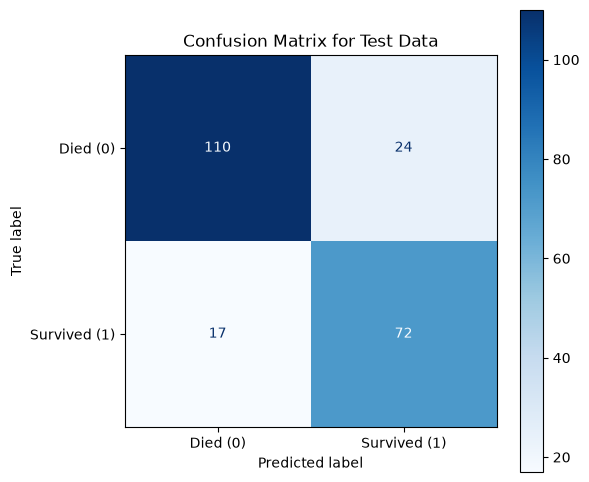

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_test = confusion_matrix(y_test, rf_test_preds)
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['Died (0)', 'Survived (1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
plt.title('Confusion Matrix for Test Data')
plt.show()

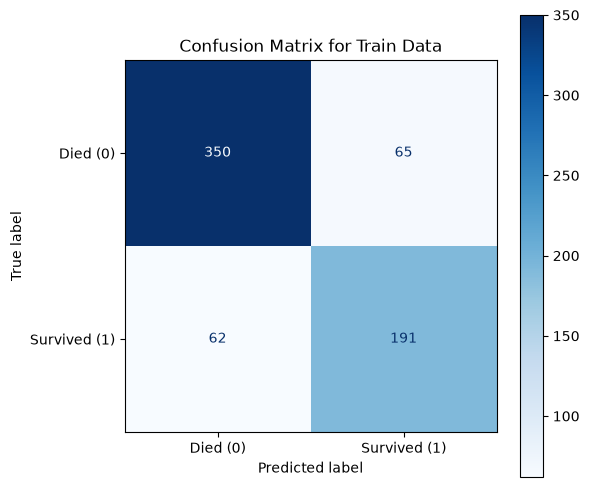

In [12]:
cm_train = confusion_matrix(rf_y, rf_best_preds)
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=['Died (0)', 'Survived (1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
plt.title('Confusion Matrix for Train Data')
plt.show()

In [15]:
from sklearn.metrics import classification_report
print(f'For Train\n: {classification_report(rf_y, rf_best_preds)}')

For Train
:               precision    recall  f1-score   support

           0       0.85      0.84      0.85       415
           1       0.75      0.75      0.75       253

    accuracy                           0.81       668
   macro avg       0.80      0.80      0.80       668
weighted avg       0.81      0.81      0.81       668



In [16]:
print(f'For Test\n: {classification_report(y_test, rf_test_preds)}')

For Test
:               precision    recall  f1-score   support

           0       0.87      0.82      0.84       134
           1       0.75      0.81      0.78        89

    accuracy                           0.82       223
   macro avg       0.81      0.81      0.81       223
weighted avg       0.82      0.82      0.82       223



In [ ]:
from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_test, rf_test_probs))

0.8807227905416737


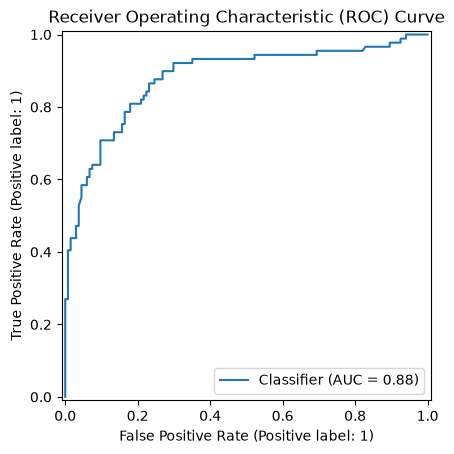

In [25]:
from sklearn.metrics import  RocCurveDisplay
RocCurveDisplay.from_predictions(y_test, rf_test_probs)
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.show()

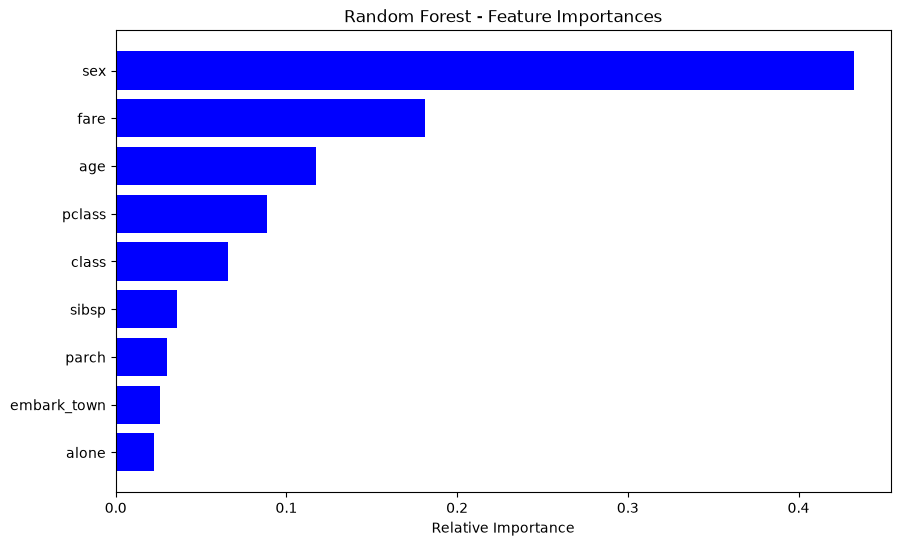

In [27]:
importances = best_model.feature_importances_
feature_names = x_train.columns
indices = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.title('Random Forest - Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()